In [1]:
from pynq import Overlay, allocate
import numpy as np
from PIL import Image
import time

# 加载 3×3 版本
ol_3x3 = Overlay('/home/xilinx/jupyter_notebooks/pynq_sobel/system_wrapper_3x3.bit')
dma_3 = ol_3x3.axi_dma_0
ip_3  = ol_3x3.sobel_filter_0

# 读取测试图
img = Image.open('/home/xilinx/jupyter_notebooks/pynq_sobel/img1.png').convert('L').resize((640, 480))
src_np = np.array(img, dtype=np.uint8)

in_buf  = allocate(shape=(480, 640), dtype=np.uint8)
out_3   = allocate(shape=(480, 640), dtype=np.uint8)
in_buf[:] = src_np

ip_3.write(0x10, 480)   # rows
ip_3.write(0x18, 640)   # cols
ip_3.write(0x20, 30)    # threshold

# 热身一次（排除首次加载开销）
ip_3.write(0x00, 0x01)
dma_3.recvchannel.transfer(out_3)
dma_3.sendchannel.transfer(in_buf)
dma_3.sendchannel.wait()
dma_3.recvchannel.wait()

# 正式计时：跑 100 次取平均
t0 = time.time()
for _ in range(100):
    out_3[:] = 0
    ip_3.write(0x00, 0x01)
    dma_3.recvchannel.transfer(out_3)
    dma_3.sendchannel.transfer(in_buf)
    dma_3.sendchannel.wait()
    dma_3.recvchannel.wait()
time_3x3 = (time.time() - t0) / 100 * 1000

result_3x3 = np.copy(out_3)
print(f"3x3 完成：{time_3x3:.2f} ms  {1000/time_3x3:.1f} FPS  边缘像素={np.count_nonzero(result_3x3)}")

3x3 完成：4.13 ms  242.3 FPS  边缘像素=125270


In [3]:
print(list(ol_5x5.ip_dict.keys()))

['sobel_filter_5x5_0', 'axi_dma_0', 'processing_system7_0']


In [4]:
# 切换加载 5×5 版本（会覆盖 PL，3×3 自动失效）
ol_5x5 = Overlay('/home/xilinx/jupyter_notebooks/pynq_sobel/system_wrapper_5x5.bit')
dma_5 = ol_5x5.axi_dma_0
ip_5  = ol_5x5.sobel_filter_5x5_0

out_5 = allocate(shape=(480, 640), dtype=np.uint8)

ip_5.write(0x10, 480)   # rows
ip_5.write(0x18, 640)   # cols
ip_5.write(0x20, 30)    # threshold（与 3×3 保持一致，保证公平对比）

# 热身
ip_5.write(0x00, 0x01)
dma_5.recvchannel.transfer(out_5)
dma_5.sendchannel.transfer(in_buf)
dma_5.sendchannel.wait()
dma_5.recvchannel.wait()

# 正式计时
t0 = time.time()
for _ in range(100):
    out_5[:] = 0
    ip_5.write(0x00, 0x01)
    dma_5.recvchannel.transfer(out_5)
    dma_5.sendchannel.transfer(in_buf)
    dma_5.sendchannel.wait()
    dma_5.recvchannel.wait()
time_5x5 = (time.time() - t0) / 100 * 1000

result_5x5 = np.copy(out_5)
print(f"5x5 完成：{time_5x5:.2f} ms  {1000/time_5x5:.1f} FPS  边缘像素={np.count_nonzero(result_5x5)}")

5x5 完成：4.19 ms  238.7 FPS  边缘像素=152914


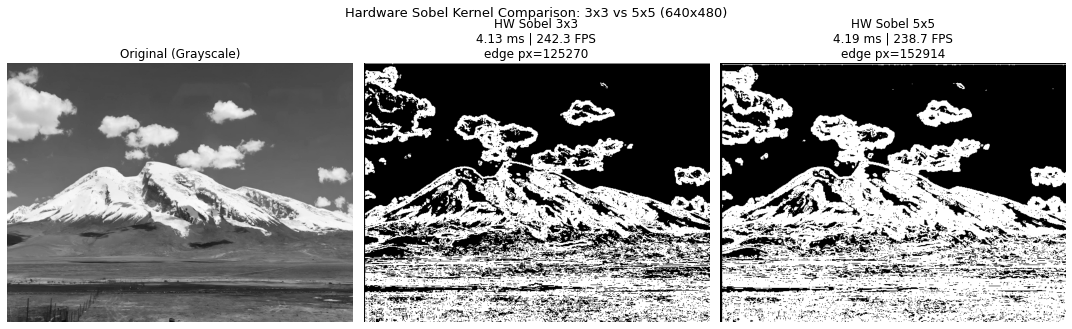


Metric                           3x3             5x5
Latency (ms)                    4.13            4.19
FPS                            242.3           238.7
Edge Pixels                   125270          152914
Latency Ratio                  1.00x           1.02x


In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(src_np, cmap='gray')
axes[0].set_title('Original (Grayscale)')
axes[0].axis('off')

axes[1].imshow(result_3x3, cmap='gray')
axes[1].set_title(f'HW Sobel 3x3\n{time_3x3:.2f} ms | {1000/time_3x3:.1f} FPS\nedge px={np.count_nonzero(result_3x3)}')
axes[1].axis('off')

axes[2].imshow(result_5x5, cmap='gray')
axes[2].set_title(f'HW Sobel 5x5\n{time_5x5:.2f} ms | {1000/time_5x5:.1f} FPS\nedge px={np.count_nonzero(result_5x5)}')
axes[2].axis('off')

plt.suptitle('Hardware Sobel Kernel Comparison: 3x3 vs 5x5 (640x480)', fontsize=13)
plt.tight_layout()
plt.savefig('/home/xilinx/jupyter_notebooks/pynq_sobel/kernel_compare_hw.png', dpi=150)
plt.show()

# 数据汇总表
print("\n" + "="*55)
print(f"{'Metric':<20} {'3x3':>15} {'5x5':>15}")
print("="*55)
print(f"{'Latency (ms)':<20} {time_3x3:>15.2f} {time_5x5:>15.2f}")
print(f"{'FPS':<20} {1000/time_3x3:>15.1f} {1000/time_5x5:>15.1f}")
print(f"{'Edge Pixels':<20} {np.count_nonzero(result_3x3):>15} {np.count_nonzero(result_5x5):>15}")
print(f"{'Latency Ratio':<20} {'1.00x':>15} {time_5x5/time_3x3:>14.2f}x")
print("="*55)